# Best Fusion Configuration

## Objective
Select the **best-performing configuration for each number of architectures ($K=1,\ldots,5$)** and each fusion method using **F1-macro** as the selection criterion. For DCMC-Fusion, the selected configuration is an architecture combination–fusion classifier pair; for the voting methods, it is the best architecture combination. Compare the 20 selected configurations in a single figure.

## Input files
Upload the following **eight CSV files** to `/content/` in Google Colab before running the notebook:

- **DCMC-Fusion:** `global_metrics_k1.csv`, `global_metrics_k2.csv`, `global_metrics_k3.csv`, `global_metrics_k4.csv`, `global_metrics_k5.csv` (124 experimental configurations in total).
- **Soft Voting:** `soft_voting_global_metrics.csv`.
- **One-Hard Voting:** `one_hard_global_metrics.csv`.
- **Weighted Averaging:** `weighted_averaging_global_metrics.csv`.

The input CSVs must contain `K` (or have K inferred from the DCMC filename), `architectures`, and `f1_macro`; the voting files also need `accuracy`, `precision_macro`, and `recall_macro` for the selected-results table.

## Outputs
- `best_configurations_by_k.csv`: five DCMC-Fusion winners, one per K.
- `best_voting_configurations_by_k.csv`: 15 voting-method winners, one per method and K.
- `best_fusion_configurations_by_k.csv`: all 20 winners in a consolidated table.
- `Fig10.png`: comparison of the best F1-macro for each method and K (300 dpi).

**Selection rule:** The maximum observed F1-macro is selected independently for each method and K. Ties retain the first occurrence in the source file. This is a descriptive selection from the supplied metrics; the notebook does not establish whether those metrics were measured on a separate validation or test partition.


## 1. Select the best DCMC-Fusion configuration for each K

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import display

DATA_DIR = Path("/content")

# Load the five DCMC-Fusion result files.
dcmc_frames = []
for k in range(1, 6):
    file_path = DATA_DIR / f"global_metrics_k{k}.csv"
    df = pd.read_csv(file_path)
    df["K"] = k
    dcmc_frames.append(df)

df_dcmc = pd.concat(dcmc_frames, ignore_index=True)
required_dcmc = {"K", "architectures", "f1_macro"}
assert required_dcmc.issubset(df_dcmc.columns), "Missing required DCMC-Fusion columns."
assert len(df_dcmc) == 124, "Expected 124 DCMC-Fusion configurations."
assert df_dcmc["f1_macro"].notna().all(), "Missing DCMC-Fusion F1-macro values."

# Select the highest-F1 configuration (architecture set and classifier) for each K.
best_indices = df_dcmc.groupby("K")["f1_macro"].idxmax()
best_dcmc = (df_dcmc.loc[best_indices]
             .sort_values("K")
             .reset_index(drop=True)
             .copy())
best_dcmc["method"] = "DCMC-Fusion"
assert len(best_dcmc) == 5

display(best_dcmc.round(4))
best_dcmc.drop(columns="method").to_csv(
    DATA_DIR / "best_configurations_by_k.csv", index=False
)
print("Saved: best_configurations_by_k.csv")

,K,architectures,classifier,accuracy,precision_macro,recall_macro,f1_macro,method
0,1,densenet121,XGBoost,0.7145,0.7514,0.7145,0.7036,DCMC-Fusion
1,2,densenet121 + vgg16,XGBoost,0.7265,0.7689,0.7265,0.7153,DCMC-Fusion
2,3,densenet121 + resnet34 + vgg16,XGBoost,0.7306,0.7787,0.7306,0.7184,DCMC-Fusion
3,4,densenet121 + inception_v3 + resnet34 + vgg16,XGBoost,0.7279,0.7725,0.7279,0.7163,DCMC-Fusion
4,5,resnet50 + densenet121 + inception_v3 + resnet...,XGBoost,0.7265,0.7662,0.7265,0.7160,DCMC-Fusion


Saved: best_configurations_by_k.csv


## 2. Select the best configuration for each voting method and K

In [2]:
# Load the three voting-method result files.
voting_files = {
    "Soft Voting": "soft_voting_global_metrics.csv",
    "One-Hard Voting": "one_hard_global_metrics.csv",
    "Weighted Averaging": "weighted_averaging_global_metrics.csv",
}

voting_winners = []
required_voting = {"K", "architectures", "accuracy", "precision_macro", "recall_macro", "f1_macro"}

for method_name, filename in voting_files.items():
    df = pd.read_csv(DATA_DIR / filename)
    assert required_voting.issubset(df.columns), f"Missing columns in {filename}."
    assert df["f1_macro"].notna().all(), f"Missing F1-macro values in {filename}."
    assert set(df["K"].astype(int)) == set(range(1, 6)), f"Unexpected K values in {filename}."

    # Select the best architectural combination independently for each K.
    best_indices = df.groupby("K")["f1_macro"].idxmax()
    selected = df.loc[best_indices].copy()
    selected["method"] = method_name
    voting_winners.append(selected[
        ["method", "K", "architectures", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
    ])

best_voting = (pd.concat(voting_winners, ignore_index=True)
               .sort_values(["K", "method"])
               .reset_index(drop=True))
assert len(best_voting) == 15
assert not best_voting.duplicated(["method", "K"]).any()

display(best_voting.round(4))
best_voting.to_csv(DATA_DIR / "best_voting_configurations_by_k.csv", index=False)
print("Saved: best_voting_configurations_by_k.csv")

,method,K,architectures,accuracy,precision_macro,recall_macro,f1_macro
0,One-Hard Voting,1,resnet50,0.6448,0.6651,0.6448,0.6335
1,Soft Voting,1,vgg16,0.5965,0.6230,0.5965,0.5736
2,Weighted Averaging,1,inception_v3,0.6193,0.6316,0.6193,0.6102
3,One-Hard Voting,2,resnet50 + resnet34,0.6542,0.6858,0.6542,0.6388
4,Soft Voting,2,inception_v3 + vgg16,0.5831,0.6144,0.5831,0.5525
5,Weighted Averaging,2,inception_v3+vgg16,0.6046,0.6139,0.6046,0.5963
6,One-Hard Voting,3,resnet50 + densenet121 + resnet34,0.6421,0.6859,0.6421,0.6197
7,Soft Voting,3,resnet50 + inception_v3 + vgg16,0.5818,0.6157,0.5818,0.5487
8,Weighted Averaging,3,resnet50+inception_v3+vgg16,0.5912,0.6004,0.5912,0.5816
9,One-Hard Voting,4,resnet50 + densenet121 + resnet34 + vgg16,0.6260,0.7761,0.6260,0.5672


Saved: best_voting_configurations_by_k.csv


## 3. Consolidate and verify the 20 winning configurations

In [3]:
# Use the preserved DCMC-Fusion winners, not a variable overwritten in a loop.
best_all = (pd.concat([best_dcmc, best_voting], ignore_index=True)
            .sort_values(["K", "method"])
            .reset_index(drop=True))

expected_methods = {"DCMC-Fusion", "Soft Voting", "One-Hard Voting", "Weighted Averaging"}
assert len(best_all) == 20, "Expected exactly 20 winning configurations."
assert set(best_all["method"]) == expected_methods, "A fusion method is missing."
assert not best_all.duplicated(["method", "K"]).any(), "Duplicate method–K combinations."
assert best_all.groupby("method")["K"].nunique().eq(5).all(), "Each method must cover K=1,...,5."

# Display the comparison table before plotting.
comparison_table = best_all.pivot(index="K", columns="method", values="f1_macro")
display(comparison_table.round(4))

best_all.to_csv(DATA_DIR / "best_fusion_configurations_by_k.csv", index=False)
print("Saved: best_fusion_configurations_by_k.csv")

method,DCMC-Fusion,One-Hard Voting,Soft Voting,Weighted Averaging
K,,,,
1,0.7036,0.6335,0.5736,0.6102
2,0.7153,0.6388,0.5525,0.5963
3,0.7184,0.6197,0.5487,0.5816
4,0.7163,0.5672,0.5237,0.5639
5,0.7160,0.5336,0.4912,0.5155


Saved: best_fusion_configurations_by_k.csv


## 4. Plot the best F1-macro by fusion method and K

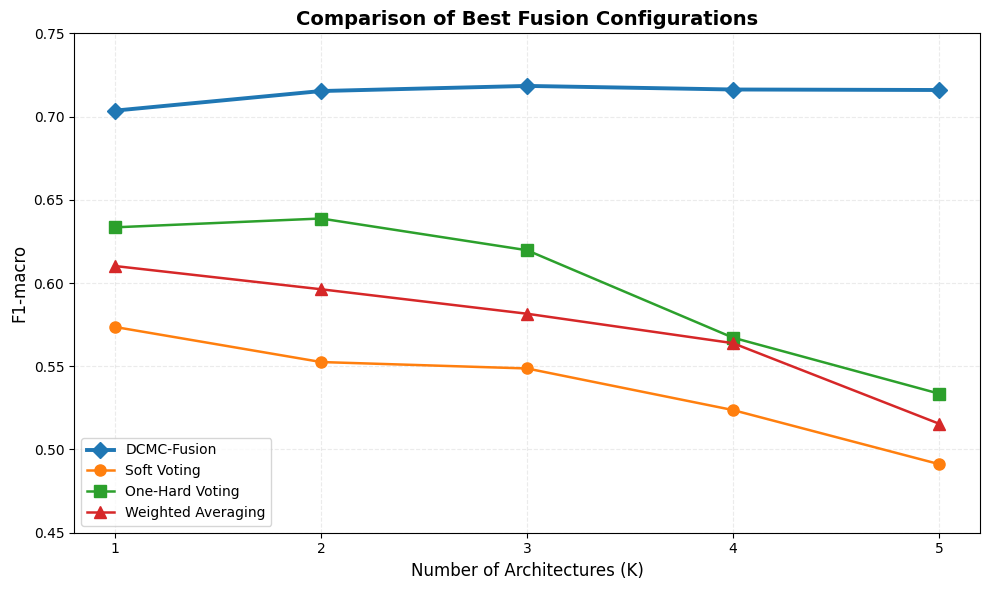

Saved: Fig10.png


In [4]:
import matplotlib.pyplot as plt

# Plot the highest observed F1-macro for each method at each K.
plot_styles = {
    "DCMC-Fusion": {"marker": "D", "linewidth": 2.8},
    "Soft Voting": {"marker": "o", "linewidth": 1.8},
    "One-Hard Voting": {"marker": "s", "linewidth": 1.8},
    "Weighted Averaging": {"marker": "^", "linewidth": 1.8},
}

fig, ax = plt.subplots(figsize=(10, 6))
for method_name, style in plot_styles.items():
    selected = best_all.loc[best_all["method"] == method_name].sort_values("K")
    assert len(selected) == 5, f"Expected five points for {method_name}."
    ax.plot(selected["K"], selected["f1_macro"],
            label=method_name, markersize=8, **style)

ax.set_title("Comparison of Best Fusion Configurations", fontsize=14, fontweight="bold")
ax.set_xlabel("Number of Architectures (K)", fontsize=12)
ax.set_ylabel("F1-macro", fontsize=12)
ax.set_xticks(range(1, 6))
ax.set_ylim(0.45, 0.75)
ax.grid(alpha=0.25, linestyle="--")
ax.legend(loc="best", frameon=True)
plt.tight_layout()
plt.savefig(DATA_DIR / "Fig10.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: Fig10.png")